In [18]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## EN4554 Assignment 2 - Convolutional Neural Networks

**Name:** Jayarathne H.A.C.N.
**Index number:** 220252U


### 0. Setup

In [24]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

In [25]:
seed = 0
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


In [26]:
# load the CIFAR-10 training set
train_data = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
X = torch.tensor(train_data.data).permute(0, 3, 1, 2).float() / 255   # shape (50000, 3, 32, 32)
y = torch.tensor(train_data.targets)

# split: 45k train, 5k validation
perm = torch.randperm(50000)
X_train, y_train = X[perm[:45000]], y[perm[:45000]]
X_val, y_val = X[perm[45000:]], y[perm[45000:]]

# normalise each channel with the TRAINING mean and std
mean = X_train.mean(dim=(0, 2, 3), keepdim=True)
std = X_train.std(dim=(0, 2, 3), keepdim=True)
X_train = (X_train - mean) / std
X_val = (X_val - mean) / std

print('train:', X_train.shape, '| val:', X_val.shape)
print('channel means:', mean.flatten())
print('channel stds :', std.flatten())

train: torch.Size([45000, 3, 32, 32]) | val: torch.Size([5000, 3, 32, 32])
channel means: tensor([0.4912, 0.4820, 0.4464])
channel stds : tensor([0.2472, 0.2436, 0.2617])


### Task 1: Backpropagation

#### (a) Linear, ReLU and softmax cross-entropy with explicit forward/backward

In [27]:
class Linear:
    def __init__(self, n_in, n_out):
        self.W = torch.randn(n_in, n_out) * np.sqrt(2 / n_in)
        self.b = torch.zeros(n_out)

    def forward(self, x):
        self.x = x 
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values
        exp = shifted.exp()
        self.probs = exp / exp.sum(dim=1, keepdim=True)
        self.y = y
        return -torch.log(self.probs[torch.arange(len(y)), y]).mean()

    def backward(self):
        N = len(self.y)
        d = self.probs.clone()
        d[torch.arange(N), self.y] -= 1
        return d / N


class MLP:
    def __init__(self, sizes, act=ReLU):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1]))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

#### (b) Gradient check

In [28]:
torch.manual_seed(0)
net = MLP([10, 8, 5, 3])
linears = [l for l in net.layers if isinstance(l, Linear)]
for l in linears:
    l.W = l.W.double()
    l.b = l.b.double()

x = torch.randn(6, 10).double()
y_small = torch.randint(0, 3, (6,))

# 1) our gradients
net.loss(x, y_small)
net.backward()

# 2) autograd gradients (copy of the same weights)
Ws = [l.W.clone().requires_grad_() for l in linears]
bs = [l.b.clone().requires_grad_() for l in linears]
h = x
for i in range(len(Ws)):
    h = h @ Ws[i] + bs[i]
    if i < len(Ws) - 1:
        h = torch.relu(h)
F.cross_entropy(h, y_small).backward()

# 3) finite differences
def numerical_grad(param, eps=1e-6):
    grad = torch.zeros_like(param)
    for idx in np.ndindex(*param.shape):
        old = param[idx].item()
        param[idx] = old + eps
        loss_plus = net.loss(x, y_small).item()
        param[idx] = old - eps
        loss_minus = net.loss(x, y_small).item()
        param[idx] = old                         # put the value back
        grad[idx] = (loss_plus - loss_minus) / (2 * eps)
    return grad

def rel_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm())).item()

print('param | err vs autograd | err vs finite diff | allclose(autograd) | allclose(finite diff)')
for i, layer in enumerate(linears):
    for name, p, mine, auto in [('W', layer.W, layer.dW, Ws[i].grad), ('b', layer.b, layer.db, bs[i].grad)]:
        num = numerical_grad(p)
        print(f'{name}{i + 1}    | {rel_error(mine, auto):.2e}         | {rel_error(mine, num):.2e}           | '
              f'{torch.allclose(mine, auto)}               | {torch.allclose(mine, num, atol=1e-6)}')

param | err vs autograd | err vs finite diff | allclose(autograd) | allclose(finite diff)
W1    | 7.04e-17         | 4.95e-10           | True               | True
b1    | 8.97e-17         | 6.20e-10           | True               | True
W2    | 9.69e-17         | 3.20e-10           | True               | True
b2    | 1.20e-16         | 6.29e-10           | True               | True
W3    | 4.86e-17         | 2.40e-10           | True               | True
b3    | 1.74e-16         | 4.28e-10           | True               | True


#### (c) Train the MLP with SGD on flattened CIFAR-10

In [29]:
def get_batches(X, y, batch_size):
    # shuffled mini-batches
    perm = torch.randperm(len(X))
    for i in range(0, len(X), batch_size):
        idx = perm[i:i + batch_size]
        yield X[idx], y[idx]

Xtr_flat = X_train.reshape(len(X_train), -1)
Xva_flat = X_val.reshape(len(X_val), -1)

torch.manual_seed(0)
net = MLP([3072, 256, 128, 10])
lr = 0.01
epochs = 20

train_losses, val_losses, val_accs = [], [], []
for epoch in range(epochs):
    total = 0
    for xb, yb in get_batches(Xtr_flat, y_train, 128):
        loss = net.loss(xb, yb)
        net.backward()
        for layer in net.layers:                 # SGD step
            if isinstance(layer, Linear):
                layer.W -= lr * layer.dW
                layer.b -= lr * layer.db
        total += loss.item() * len(xb)
    train_losses.append(total / len(Xtr_flat))
    val_losses.append(net.loss(Xva_flat, y_val).item())
    val_accs.append((net.forward(Xva_flat).argmax(1) == y_val).float().mean().item())
    print(f'epoch {epoch + 1:2d} | train loss {train_losses[-1]:.4f} | val loss {val_losses[-1]:.4f} | val acc {val_accs[-1]:.4f}')

epoch  1 | train loss 1.8317 | val loss 1.7267 | val acc 0.3908
epoch  2 | train loss 1.5871 | val loss 1.6454 | val acc 0.4228
epoch  3 | train loss 1.4880 | val loss 1.6113 | val acc 0.4336
epoch  4 | train loss 1.4175 | val loss 1.5665 | val acc 0.4552
epoch  5 | train loss 1.3595 | val loss 1.5455 | val acc 0.4656
epoch  6 | train loss 1.3111 | val loss 1.5236 | val acc 0.4780
epoch  7 | train loss 1.2681 | val loss 1.5128 | val acc 0.4818
epoch  8 | train loss 1.2295 | val loss 1.5184 | val acc 0.4784
epoch  9 | train loss 1.1932 | val loss 1.5212 | val acc 0.4772
epoch 10 | train loss 1.1597 | val loss 1.4973 | val acc 0.4878
epoch 11 | train loss 1.1277 | val loss 1.5207 | val acc 0.4842
epoch 12 | train loss 1.0972 | val loss 1.4949 | val acc 0.4944
epoch 13 | train loss 1.0666 | val loss 1.4858 | val acc 0.4974
epoch 14 | train loss 1.0370 | val loss 1.5051 | val acc 0.4922
epoch 15 | train loss 1.0113 | val loss 1.5051 | val acc 0.4966
epoch 16 | train loss 0.9846 | val loss 

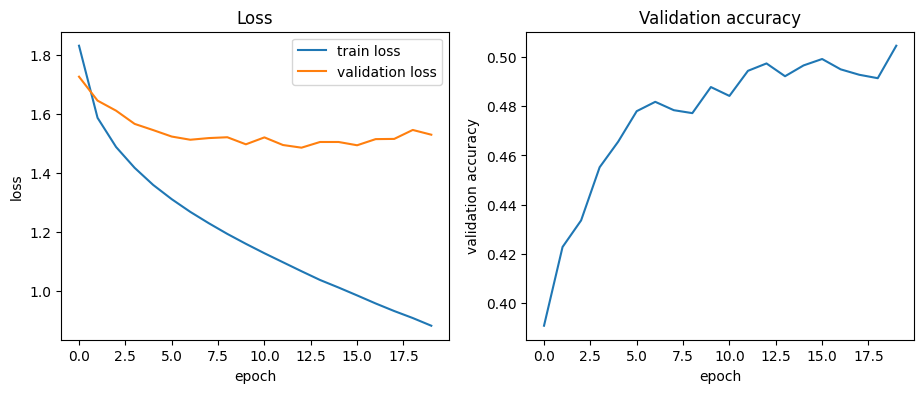

Final validation accuracy: 0.5045999884605408


In [30]:
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='train loss')
plt.plot(val_losses, label='validation loss')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.title('Loss'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(val_accs)
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.title('Validation accuracy')
plt.show()
print('Final validation accuracy:', val_accs[-1])

#### (d) Per-layer gradient norms of a 10-layer MLP: sigmoid vs ReLU

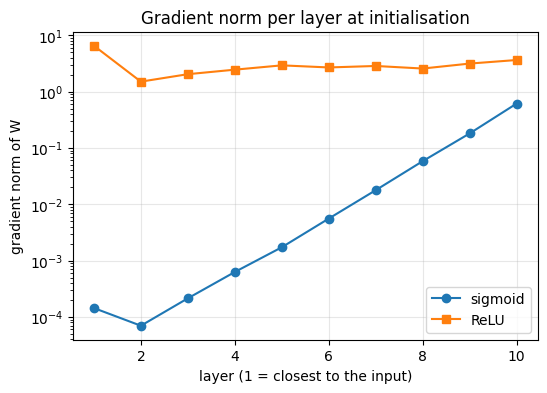

sigmoid layer 1 / layer 10 gradient ratio: 0.00023447254273657492
ReLU layer 1 / layer 10 gradient ratio: 1.792911587300411


In [31]:
class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)

xb, yb = Xtr_flat[:128], y_train[:128]
sizes = [3072] + [100] * 9 + [10]

norms = {}
for name, act in [('sigmoid', Sigmoid), ('ReLU', ReLU)]:
    torch.manual_seed(0)
    deep_net = MLP(sizes, act=act)
    deep_net.loss(xb, yb)
    deep_net.backward()
    norms[name] = [l.dW.norm().item() for l in deep_net.layers if isinstance(l, Linear)]

layers = range(1, 11)
plt.figure(figsize=(6, 4))
plt.semilogy(layers, norms['sigmoid'], 'o-', label='sigmoid')
plt.semilogy(layers, norms['ReLU'], 's-', label='ReLU')
plt.xlabel('layer (1 = closest to the input)')
plt.ylabel('gradient norm of W')
plt.title('Gradient norm per layer at initialisation')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

for name in norms:
    print(name, 'layer 1 / layer 10 gradient ratio:', norms[name][0] / norms[name][-1])